<a href="https://colab.research.google.com/github/pari-plan/Student_Marks_Prediction_ML.ipynb/blob/main/ML_STUDENTS_MARKS_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("ML project libraries imported successfully!")


ML project libraries imported successfully!


In [2]:

# Sample data: study hours and marks out of 100
data = {
    "Study_Hours": [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
        1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 11
    ],
    "Marks": [
        20, 25, 35, 40, 50, 55, 65, 70, 80, 85,
        22, 30, 38, 48, 52, 62, 68, 78, 82, 90
    ]
}

df = pd.DataFrame(data)

print(df.head())
print("\nTotal records:", len(df))


   Study_Hours  Marks
0          1.0     20
1          2.0     25
2          3.0     35
3          4.0     40
4          5.0     50

Total records: 20


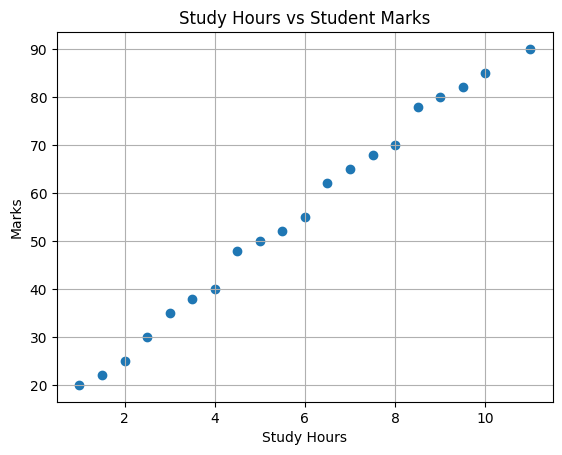

In [3]:

plt.scatter(df["Study_Hours"], df["Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Student Marks")
plt.grid(True)
plt.show()


In [4]:

X = df[["Study_Hours"]]
y = df["Marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Model training completed!
Training records: 16
Testing records: 4


In [5]:

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 3))


Mean Absolute Error: 2.02
Root Mean Squared Error: 2.35
R2 Score: 0.991


In [6]:

hours = float(input("Enter study hours: "))

if hours < 0 or hours > 24:
    print("Please enter study hours between 0 and 24.")
else:
    predicted_marks = model.predict(
        pd.DataFrame({"Study_Hours": [hours]})
    )[0]

    predicted_marks = max(0, min(100, predicted_marks))

    print("Predicted marks:", round(predicted_marks, 2), "/ 100")


Enter study hours: 6
Predicted marks: 56.19 / 100


   Actual Marks  Predicted Marks
0            20            19.81
1            78            74.38
2            62            59.83
3            25            27.09


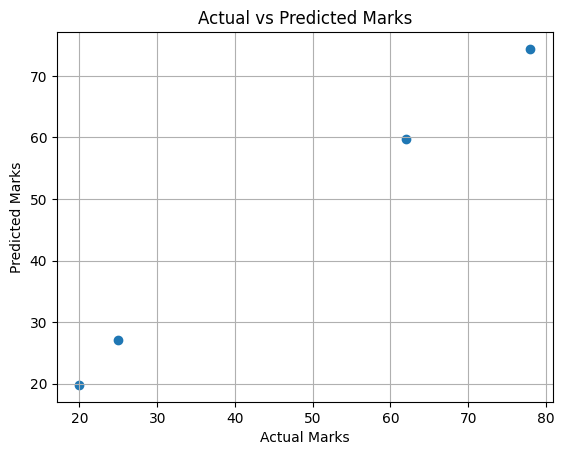

In [7]:

results = pd.DataFrame({
    "Actual Marks": y_test.to_numpy(),
    "Predicted Marks": np.round(predictions, 2)
})

print(results)

plt.scatter(y_test, predictions)
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.grid(True)
plt.show()
